# Chlorella vulgaris in Zoogle: where do 6,322 / 682 / 1,209 come from?

This notebook reproduces the numbers quoted in the Chlorella phenotyping pub from the Zoogle
export `zoogle-Chlorella-vulgaris.tsv` (one row per Chlorella homolog × human protein in the
same gene family).

**Key columns**

- `gene_family`: NovelTree orthogroup
- `ref_protein` / `hgnc_gene_symbol`: the human protein being compared to
- `within_gene_family_percentile`: phylogenetic-distance-corrected similarity (lower = more unexpectedly similar)
- `portfolio_rank`: rank of this Chlorella homolog among all homologs of that human protein across the 62 non-human organisms
- `orthogroup_homolog_rank`: rank of this homolog among the Chlorella homologs of the same human protein (1 = best Chlorella homolog)


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("zoogle-Chlorella-vulgaris.tsv", sep="\t")
print(f"{len(df):,} rows, {df.gene_family.nunique():,} gene families, "
      f"{df.ref_protein.nunique():,} human proteins, "
      f"{df.hgnc_gene_symbol.nunique(dropna=False):,} HGNC symbols")
df.head()

15,643 rows, 2,767 gene families, 6,324 human proteins, 6,322 HGNC symbols


,gene_family,nonref_species,nonref_protein,ref_protein,trait_dist,within_gene_family_percentile,organism_rank,portfolio_rank,orthogroup_homolog_rank,orthogroup_homolog_count,hgnc_gene_symbol
0,OG0000020,Chlorella-vulgaris,KAI3436855.1,O60662,0.000252,0.000022,1.0,1.0,1.0,2,KLHL41
1,OG0000018,Chlorella-vulgaris,KAI3425379.1,P35580,0.003416,0.000026,2.0,1.0,1.0,2,MYH10
2,OG0000013,Chlorella-vulgaris,KAI3438617.1,Q13131,0.000616,0.000034,3.0,1.0,1.0,15,PRKAA1
3,OG0000030,Chlorella-vulgaris,KAI3426853.1,P18031,0.005595,0.000035,4.0,1.0,1.0,1,PTPN1
4,OG0000023,Chlorella-vulgaris,KAI3429443.1,Q9BV47,0.002092,0.000037,5.0,1.0,1.0,5,DUSP26


## Reproduce the pub numbers

Keep only the best Chlorella homolog for each human protein, then count how often it ranks
first or top-3 across the organism portfolio.

In [2]:
best = df[df.orthogroup_homolog_rank == 1].copy()

n_genes = best.hgnc_gene_symbol.nunique(dropna=False)
n_rank1 = (best.portfolio_rank == 1).sum()
n_top3 = (best.portfolio_rank <= 3).sum()

print(f"Human genes with a Chlorella homolog: {n_genes:,}")
print(f"Chlorella homolog ranks #1 across organisms: {n_rank1:,}")
print(f"Chlorella homolog ranks in top 3:            {n_top3:,}")

Human genes with a Chlorella homolog: 6,322
Chlorella homolog ranks #1 across organisms: 682
Chlorella homolog ranks in top 3:            1,209


So **6,322 is the number of human genes (not gene families) with a Chlorella homolog in Zoogle**, and
no disease filter is involved. If the pub is written at the gene-family level instead, use the
counts below (one best homolog per orthogroup).

In [3]:
fam = df.sort_values("portfolio_rank").groupby("gene_family").first()
print(f"Gene families: {len(fam):,}")
print(f"Families where Chlorella ranks #1: {(fam.portfolio_rank == 1).sum():,}")
print(f"Families where Chlorella is top 3: {(fam.portfolio_rank <= 3).sum():,}")

Gene families: 2,767
Families where Chlorella ranks #1: 601
Families where Chlorella is top 3: 997


## Where does Chlorella's best homolog rank?

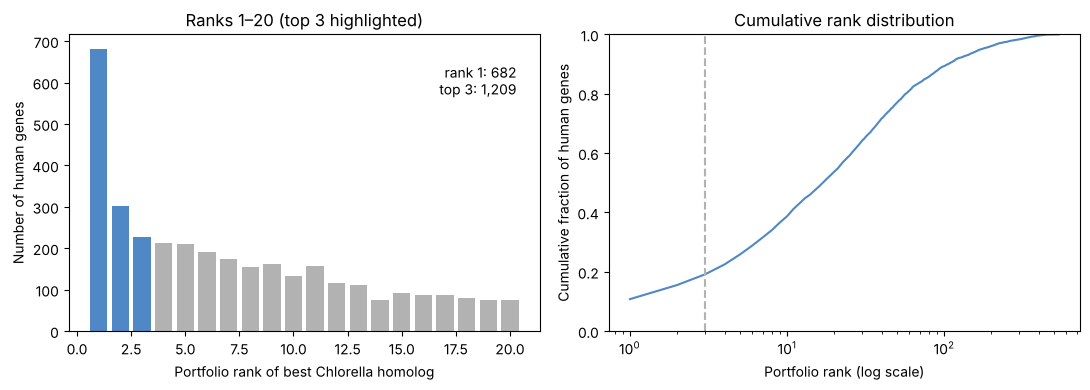

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Left: how many human genes have a Chlorella homolog at each portfolio rank (ranks 1–20)
counts = best.portfolio_rank.value_counts().sort_index()
top = counts.loc[counts.index <= 20]
colors = ["#5088C5" if r <= 3 else "#B2B2B2" for r in top.index]
axes[0].bar(top.index, top.values, color=colors)
axes[0].set_xlabel("Portfolio rank of best Chlorella homolog")
axes[0].set_ylabel("Number of human genes")
axes[0].set_title("Ranks 1–20 (top 3 highlighted)")
axes[0].text(0.95, 0.9, f"rank 1: {n_rank1:,}\ntop 3: {n_top3:,}",
             transform=axes[0].transAxes, ha="right", va="top")

# Right: cumulative fraction of human genes at or below each rank
cum = counts.cumsum() / counts.sum()
axes[1].plot(cum.index, cum.values, color="#5088C5")
axes[1].set_xscale("log")
axes[1].set_xlabel("Portfolio rank (log scale)")
axes[1].set_ylabel("Cumulative fraction of human genes")
axes[1].set_title("Cumulative rank distribution")
axes[1].axvline(3, color="#B2B2B2", ls="--")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

## Is rank #1 driven by tiny orthogroups?

Chlorella ranking first is more meaningful when the human protein has many homologs across
organisms. Check how rank-1 hits are distributed over orthogroup size.

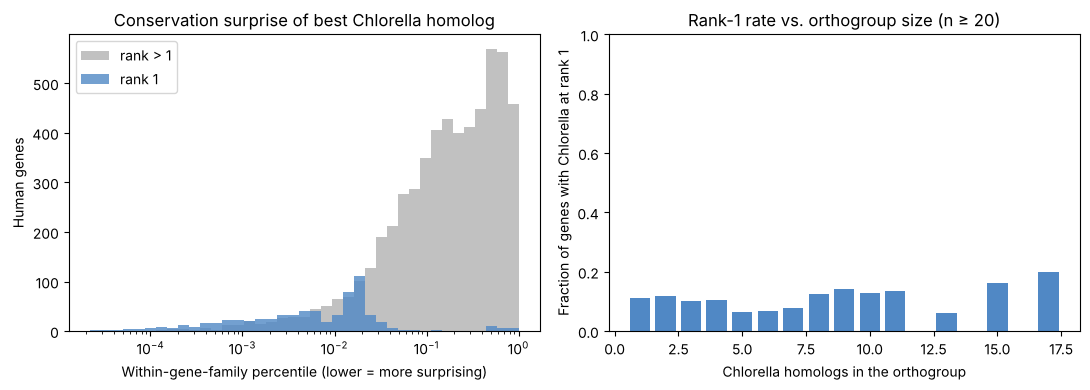

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Left: within-family percentile of best homolog, rank-1 vs the rest
r1 = best[best.portfolio_rank == 1].within_gene_family_percentile
rest = best[best.portfolio_rank > 1].within_gene_family_percentile
import numpy as np
bins = np.logspace(np.log10(best.within_gene_family_percentile.min()), 0, 40)
axes[0].hist(rest, bins=bins, color="#B2B2B2", alpha=0.8, label="rank > 1")
axes[0].hist(r1, bins=bins, color="#5088C5", alpha=0.8, label="rank 1")
axes[0].set_xscale("log")
axes[0].set_xlabel("Within-gene-family percentile (lower = more surprising)")
axes[0].set_ylabel("Human genes")
axes[0].set_title("Conservation surprise of best Chlorella homolog")
axes[0].legend()

# Right: fraction of genes where Chlorella is rank 1, by number of Chlorella homologs in the family
grp = best.groupby("orthogroup_homolog_count").portfolio_rank.agg(
    n="size", frac_rank1=lambda s: (s == 1).mean())
grp = grp[grp.n >= 20]
axes[1].bar(grp.index, grp.frac_rank1, color="#5088C5")
axes[1].set_xlabel("Chlorella homologs in the orthogroup")
axes[1].set_ylabel("Fraction of genes with Chlorella at rank 1")
axes[1].set_title("Rank-1 rate vs. orthogroup size (n ≥ 20)")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

## Example genes named in the pub draft

In [6]:
examples = ["CDK6", "HSPH1", "PAK1", "FOXO1", "PRKAA1", "CSNK1E", "USP46"]
(best[best.hgnc_gene_symbol.isin(examples)]
     .set_index("hgnc_gene_symbol")
     .loc[examples, ["gene_family", "nonref_protein", "ref_protein",
                     "within_gene_family_percentile", "portfolio_rank", "orthogroup_homolog_count"]])

,gene_family,nonref_protein,ref_protein,within_gene_family_percentile,portfolio_rank,orthogroup_homolog_count
hgnc_gene_symbol,,,,,,
CDK6,OG0000016,KAI3435733.1,Q00534,0.000066,1.0,11
HSPH1,OG0000049,KAI3438271.1,Q92598,0.000103,1.0,9
PAK1,OG0000022,KAI3430720.1,Q13153,0.000043,1.0,5
FOXO1,OG0000035,KAI3434776.1,Q12778,0.000122,3.0,1
PRKAA1,OG0000013,KAI3438617.1,Q13131,0.000034,1.0,15
CSNK1E,OG0000087,KAI3428793.1,P49674,0.000151,1.0,3
USP46,OG0000101,KAI3437589.1,P62068,0.000136,1.0,5
